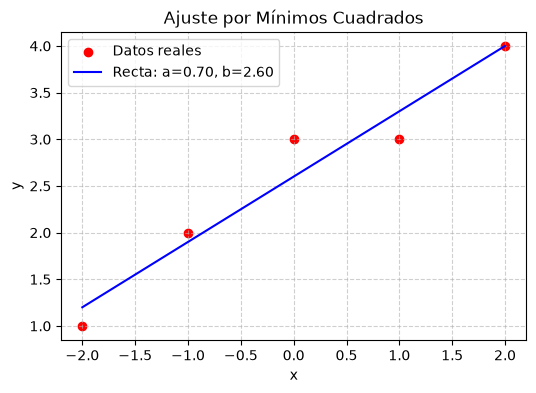

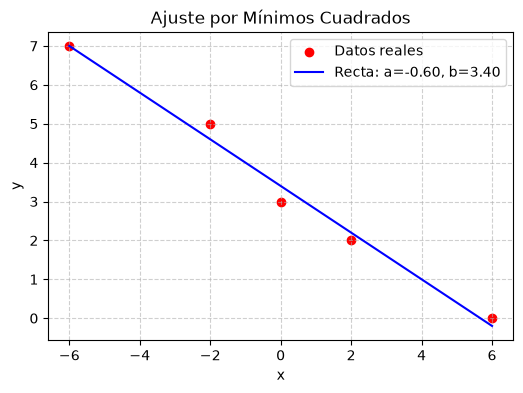

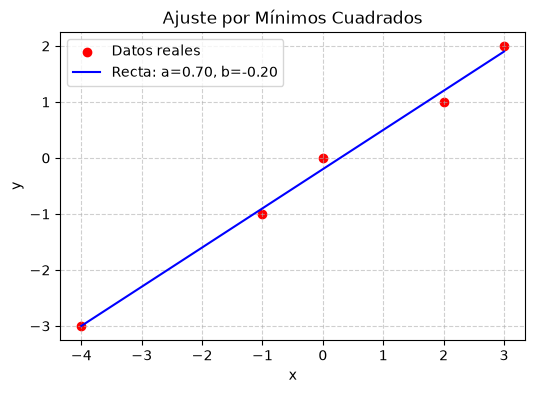

In [1]:
# PUNTO 1
import matplotlib.pyplot as plt

def recta (x,y):
  n = len(x)
  sumatoriaX = sum(x)
  sumatoriaY = sum(y)

  sumaXY = 0
  sumax2 = 0

  for i in range(n):
      sumaXY += x[i] * y[i]
      sumax2 += x[i] ** 2

  a = (n * sumaXY - sumatoriaX * sumatoriaY) / (n * sumax2 - sumatoriaX ** 2)
  b = (sumatoriaY - a * sumatoriaX) / n

  rectaY = []
  for valor_x in x:
        rectaY.append(a * valor_x + b)

  plt.figure(figsize=(6, 4))
  plt.scatter(x, y, color='red', label='Datos reales')
  plt.plot(x, rectaY, color='blue', label=f'Recta: a={a:.2f}, b={b:.2f}')

  plt.title('Ajuste por Mínimos Cuadrados')
  plt.xlabel('x')
  plt.ylabel('y')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.legend()
  plt.show()


V1x= [-2,-1,0,1,2]
V1y= [1,2,3,3,4]

V2x= [-6,-2,0,2,6]
V2y= [7,5,3,2,0]

V3x= [-4,-1,0,2,3]
V3y= [-3,-1,0,1,2]

recta(V1x, V1y)
recta(V2x, V2y)
recta(V3x, V3y)

A = 0.39120230054281424
C = 1.5799091528746367
Función: y = 1.5799 * e^(0.3912 * x)


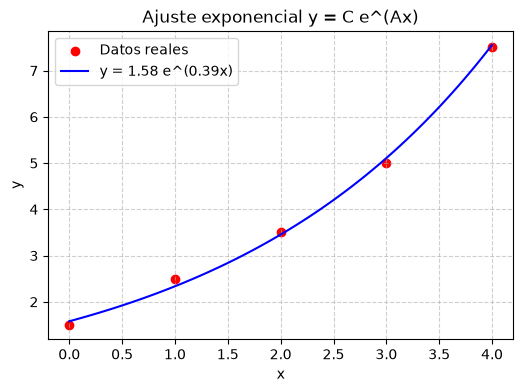

In [2]:
# PUNTO 2
import matplotlib.pyplot as plt
import math

def exponencial(x, y):
  n = len(x)

  Y = []
  for i in range(n):
    Y.append(math.log(y[i]))   # logaritmo natural

  sumatoriaX = sum(x)
  sumatoriaY = sum(Y)

  sumaXY = 0
  sumax2 = 0
  for i in range(n):
    sumaXY += x[i] * Y[i]
    sumax2 += x[i] ** 2

  A = (n * sumaXY - sumatoriaX * sumatoriaY) / (n * sumax2 - sumatoriaX ** 2)
  b = (sumatoriaY - A * sumatoriaX) / n
  C = math.exp(b)

  xs = []
  curvaY = []
  pasos = 100
  xmin, xmax = x[0], x[-1]
  for i in range(pasos + 1):
    valor_x = xmin + (xmax - xmin) * i / pasos
    xs.append(valor_x)
    curvaY.append(C * math.exp(A * valor_x))

  print(f"A = {A}")
  print(f"C = {C}")
  print(f"Función: y = {C:.4f} * e^({A:.4f} * x)")

  plt.figure(figsize=(6, 4))
  plt.scatter(x, y, color='red', label='Datos reales')
  plt.plot(xs, curvaY, color='blue', label=f'y = {C:.2f} e^({A:.2f}x)')
  plt.title('Ajuste exponencial y = C e^(Ax)')
  plt.xlabel('x')
  plt.ylabel('y')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.legend()
  plt.show()

x = [0, 1, 2, 3, 4]
y = [1.5, 2.5, 3.5, 5.0, 7.5]

exponencial(x, y)


Grado 1
Coeficientes: [0.9295140427297245, 0.5281020535158673]
p(x) = 0.9295*x^0 + 0.5281*x^1


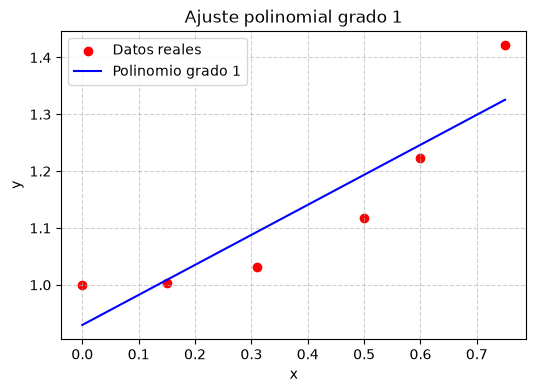


Grado 2
Coeficientes: [1.0113409927932246, -0.32569875070863474, 1.1473303054585995]
p(x) = 1.0113*x^0 + -0.3257*x^1 + 1.1473*x^2


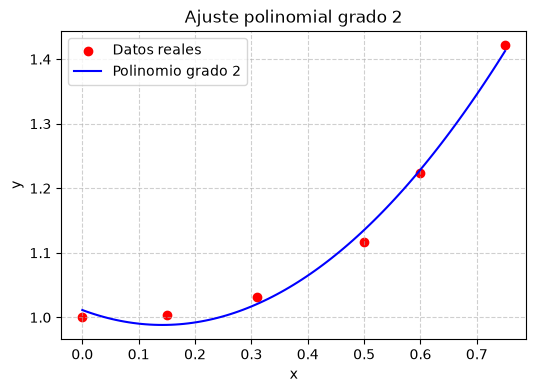


Grado 3
Coeficientes: [1.0004398051840666, -0.0015409860474889236, -0.011505674519446618, 1.0210225642113375]
p(x) = 1.0004*x^0 + -0.0015*x^1 + -0.0115*x^2 + 1.0210*x^3


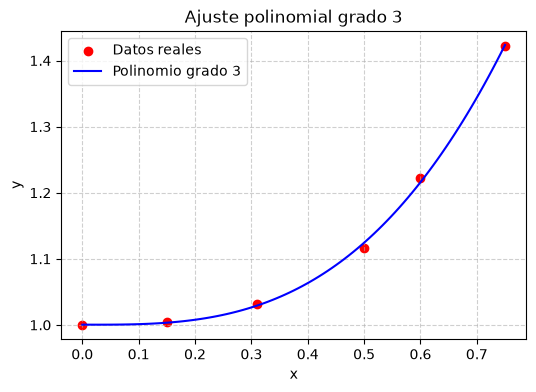


Grado 4
Coeficientes: [0.999495149544347, 0.11069898428352026, -0.8254244767806216, 2.7828842802365967, -1.167916389468222]
p(x) = 0.9995*x^0 + 0.1107*x^1 + -0.8254*x^2 + 2.7829*x^3 + -1.1679*x^4


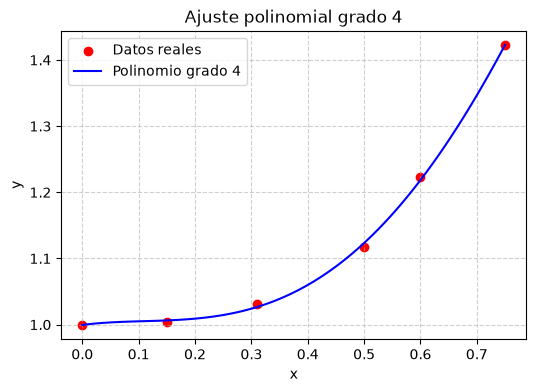

In [3]:
# PUNTO 3
import matplotlib.pyplot as plt

def gauss(A, b):
  n = len(b)
  M = []
  for i in range(n):
    fila = A[i][:]
    fila.append(b[i])
    M.append(fila)

  for col in range(n):
    piv = col
    for r in range(col + 1, n):
      if abs(M[r][col]) > abs(M[piv][col]):
        piv = r
    M[col], M[piv] = M[piv], M[col]

    div = M[col][col]
    for j in range(col, n + 1):
      M[col][j] = M[col][j] / div

    for r in range(n):
      if r != col:
        f = M[r][col]
        for j in range(col, n + 1):
          M[r][j] = M[r][j] - f * M[col][j]

  coef = []
  for i in range(n):
    coef.append(M[i][n])
  return coef

def evaluarPolinomio(coef, x):
  y = 0
  for k in range(len(coef)):
    y = y + coef[k] * (x ** k)
  return y

def polinomio(x, y, grado):
  m = grado
  n_coef = m + 1

  # ecuaciones normales
  A = []
  b = []
  for i in range(n_coef):
    fila = []
    for j in range(n_coef):
      s = 0
      for t in range(len(x)):
        s = s + (x[t] ** (i + j))
      fila.append(s)
    A.append(fila)

    s = 0
    for t in range(len(x)):
      s = s + y[t] * (x[t] ** i)
    b.append(s)

  coef = gauss(A, b)

  print(f"\nGrado {grado}")
  print("Coeficientes:", coef)

  texto = "p(x) ="
  for k in range(len(coef)):
    texto = texto + f" {coef[k]:.4f}*x^{k}"
    if k < len(coef) - 1:
      texto = texto + " +"
  print(texto)

  # curva suave
  xs = []
  ys = []
  pasos = 100
  xmin, xmax = min(x), max(x)
  for i in range(pasos + 1):
    valor_x = xmin + (xmax - xmin) * i / pasos
    xs.append(valor_x)
    ys.append(evaluarPolinomio(coef, valor_x))

  plt.figure(figsize=(6, 4))
  plt.scatter(x, y, color='red', label='Datos reales')
  plt.plot(xs, ys, color='blue', label=f'Polinomio grado {grado}')
  plt.title(f'Ajuste polinomial grado {grado}')
  plt.xlabel('x')
  plt.ylabel('y')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.legend()
  plt.show()

x = [0, 0.15, 0.31, 0.5, 0.6, 0.75]
y = [1.0, 1.004, 1.031, 1.117, 1.223, 1.422]

polinomio(x, y, 1)
polinomio(x, y, 2)
polinomio(x, y, 3)
polinomio(x, y, 4)

A = 1.4988973721525625
C = 0.20125843717483927
Función: T = 0.201258 * x^(1.498897)


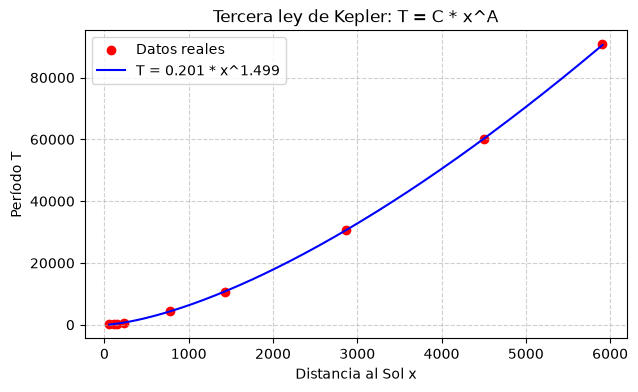

In [4]:
# PUNTO 4
import matplotlib.pyplot as plt
import math

def kepler(x, T):
  n = len(x)

  X = []
  Y = []
  for i in range(n):
    X.append(math.log(x[i]))
    Y.append(math.log(T[i]))

  sumatoriaX = sum(X)
  sumatoriaY = sum(Y)

  sumaXY = 0
  sumax2 = 0
  for i in range(n):
    sumaXY += X[i] * Y[i]
    sumax2 += X[i] ** 2

  A = (n * sumaXY - sumatoriaX * sumatoriaY) / (n * sumax2 - sumatoriaX ** 2)
  b = (sumatoriaY - A * sumatoriaX) / n
  C = math.exp(b)

  xs = []
  Ts = []
  pasos = 200
  xmin, xmax = min(x), max(x)
  for i in range(pasos + 1):
    valor_x = xmin + (xmax - xmin) * i / pasos
    xs.append(valor_x)
    Ts.append(C * (valor_x ** A))

  print(f"A = {A}")
  print(f"C = {C}")
  print(f"Función: T = {C:.6f} * x^({A:.6f})")

  plt.figure(figsize=(7, 4))
  plt.scatter(x, T, color='red', label='Datos reales')
  plt.plot(xs, Ts, color='blue', label=f'T = {C:.3f} * x^{A:.3f}')
  plt.title('Tercera ley de Kepler: T = C * x^A')
  plt.xlabel('Distancia al Sol x')
  plt.ylabel('Período T')
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.legend()
  plt.show()

x = [57.59, 108.11, 149.57, 227.84, 778.14, 1427.0, 2870.3, 4499.9, 5909.0]
T = [87.99, 224.7, 365.26, 686.98, 4332.4, 10759, 30684, 60188, 90710]

kepler(x, T)